In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X= np.array([-5,-4,-3,-2,-1,0,1,2,3,4,5])

In [3]:
type(X)

numpy.ndarray

In [4]:
def threshold(x):
    return np.where(x>=0,1,0)

In [5]:
y_threshold=threshold(X)

In [6]:
print("Input",X)
print("Threshold:",y_threshold)

Input [-5 -4 -3 -2 -1  0  1  2  3  4  5]
Threshold: [0 0 0 0 0 1 1 1 1 1 1]


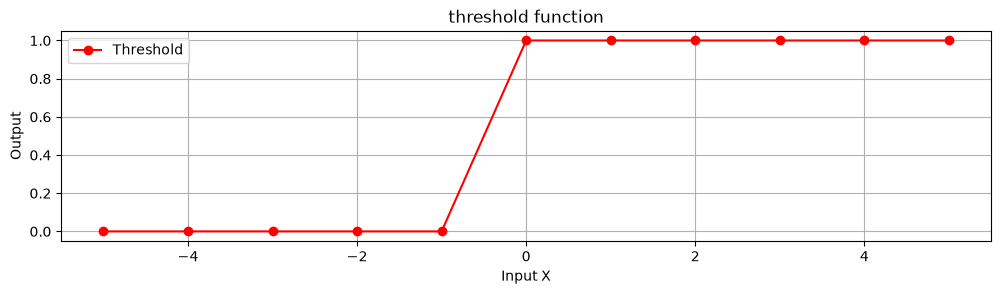

In [7]:
plt.figure(figsize=(12,6))

plt.subplot(2,1,1)
plt.plot(X,y_threshold, 'ro-',label='Threshold')
plt.xlabel("Input X")
plt.ylabel("Output")
plt.title('threshold function')
plt.grid()
plt.legend()

In [8]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

In [9]:
y_sigmoid=sigmoid(X)

In [10]:
print("Input:",X)
print("Sigmoid",y_sigmoid)

Input: [-5 -4 -3 -2 -1  0  1  2  3  4  5]
Sigmoid [0.00669285 0.01798621 0.04742587 0.11920292 0.26894142 0.5
 0.73105858 0.88079708 0.95257413 0.98201379 0.99330715]


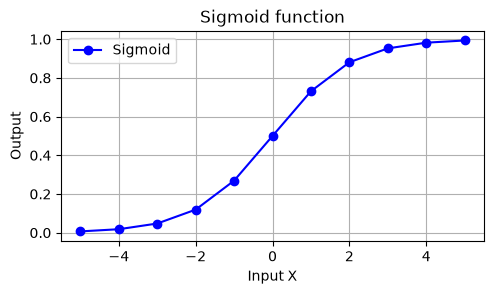

In [11]:
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.plot(X,y_sigmoid,'bo-',label='Sigmoid')
plt.xlabel("Input X")
plt.ylabel("Output")
plt.title("Sigmoid function")
plt.grid()
plt.legend()

In [12]:
def relu(x):
    return np.maximum(0,x)

In [13]:
y_relu=relu(X)

In [14]:
print("Input:",X)
print("Relu:",y_relu)

Input: [-5 -4 -3 -2 -1  0  1  2  3  4  5]
Relu: [0 0 0 0 0 0 1 2 3 4 5]


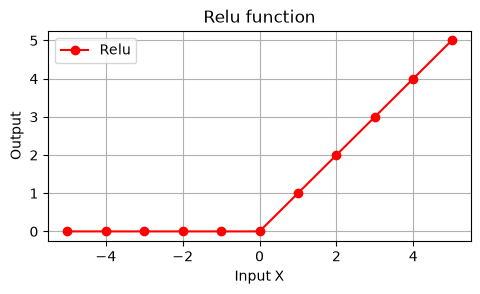

In [15]:
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.plot(X,y_relu,'ro-',label='Relu')
plt.xlabel("Input X")
plt.ylabel("Output")
plt.title("Relu function")
plt.grid()
plt.legend()

In [16]:
def tanh(x):
    return np.tanh(x)

In [17]:
y_tanh=tanh(X)

In [18]:
print("Input:",X)
print("Tanh:",y_tanh)

Input: [-5 -4 -3 -2 -1  0  1  2  3  4  5]
Tanh: [-0.9999092  -0.9993293  -0.99505475 -0.96402758 -0.76159416  0.
  0.76159416  0.96402758  0.99505475  0.9993293   0.9999092 ]


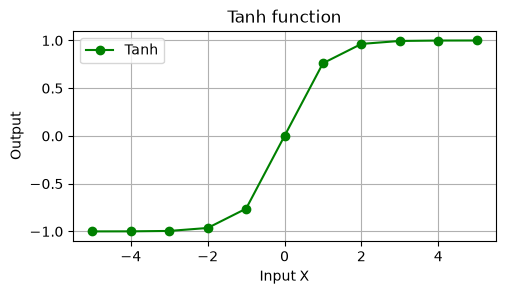

In [19]:
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.plot(X,y_tanh,'go-',label='Tanh')
plt.xlabel("Input X")
plt.ylabel("Output")
plt.title("Tanh function")
plt.grid()
plt.legend()

In [21]:
import pandas as pd
import tensorflow as tf

In [22]:
tf.__version__

'2.22.0-rc0'

In [23]:
df = pd.read_excel('Churn_Modelling.xlsx')

In [24]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
LabelEncoder
le = LabelEncoder()

In [ ]:
X[:,2] = le.fit_transform(X[:,2])


In [ ]:
print(X)

[-5 -4 -3 -2 -1  0  1  2  3  4  5]


In [ ]:
X = df.iloc[:, 3:-1].values
y = df.iloc[:, -1].values

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


In [ ]:
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [1])], remainder='passthrough')

In [ ]:
X = np.array(ct.fit_transform(X))

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
sc = StandardScaler()

In [ ]:
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# ANN Model

# Adding The First Input Layer

In [ ]:
ann = tf.keras.models.Sequential()

In [ ]:
ann.add(tf.keras.layers.Dense(units=6,activation='relu'))

# Add The Outer Layer 

In [ ]:
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# Training The ANN
# Compiling The ANN

In [ ]:
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
ann.fit(X_train,y_train,batch_size=32,epochs=100)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7144 - loss: 0.5875
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7993 - loss: 0.4796
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8048 - loss: 0.4469
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8092 - loss: 0.4332
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8135 - loss: 0.4252
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8175 - loss: 0.4189
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8202 - loss: 0.4133
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8216 - loss: 0.4083
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8244 - loss: 0.4037
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8260 - loss: 0.3997
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8263 - loss: 0.3962
Epoch 12/100
250/250 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
print(ann.predict(sc.transform([[1,0,0,600,1,40,3,60000,2,1,1,50000]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
[[0.06364752]]


In [ ]:
print(ann.predict(sc.transform([[1,0,0,600,1,40,3,60000,2,1,1,50000]]))>0.5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
[[False]]


In [ ]:
y_pred=ann.predict(X_test)
y_pred=(y_pred>0.5)
print(np.concatenate((y_pred.reshape(len(y_pred),1),y_test.reshape(len(y_test),1)),1))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
[[0 0]
 [0 1]
 [0 0]
 ...
 [0 0]
 [0 0]
 [0 0]]


In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score
cm=confusion_matrix(y_test,y_pred)
print(cm)
accuracy_score(y_test,y_pred)

[[1502   93]
 [ 191  214]]


0.858